Dataset: [https://www.kaggle.com/competitions/ieee-fraud-detection](https://www.kaggle.com/competitions/ieee-fraud-detection)

In [1]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["axes.prop_cycle"] = plt.cycler(color=["#20B2AA"])

In [2]:
IDENTITY_DATA = Path("../data/raw/train_identity.csv")
TRANSACTION_DATA = Path("../data/raw/train_transaction.csv")

df_identity = pd.read_csv(IDENTITY_DATA)
df_transaction = pd.read_csv(TRANSACTION_DATA)

In [3]:
print("Shape of identity df: ", df_identity.shape)
print("Shape of transaction df: ", df_transaction.shape)

Shape of identity df:  (144233, 41)
Shape of transaction df:  (590540, 394)


In [4]:
df_identity.head()

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


In [5]:
df_transaction.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
transaction_cols = [
    "TransactionID",
    "isFraud",
    "TransactionDT",
    "TransactionAmt",
    "ProductCD"
]

identity_cols = [
    "TransactionID",
    "DeviceType",
    "DeviceInfo",
    "id_30",
    "id_31",
    "id_33",
    "id_34"
]

df_merged = df_transaction[transaction_cols].merge(
    df_identity[identity_cols],
    on="TransactionID",
    how="left",
    validate="one_to_one"
)

print("Merged shape:", df_merged.shape)
print("Transactions with identity data:", df_merged["TransactionID"].isin(df_identity["TransactionID"]).sum())

df_merged.head()

Merged shape: (590540, 11)
Transactions with identity data: 144233


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,DeviceType,DeviceInfo,id_30,id_31,id_33,id_34
0,2987000,0,86400,68.5,W,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,mobile,SAMSUNG SM-G892A Build/NRD90M,Android 7.0,samsung browser 6.2,2220x1080,match_status:2


In [7]:
df_merged.dtypes.to_frame("dtype")

,dtype
TransactionID,int64
isFraud,int64
TransactionDT,int64
TransactionAmt,float64
ProductCD,object
DeviceType,object
DeviceInfo,object
id_30,object
id_31,object
id_33,object


In [8]:
missing_stats = pd.DataFrame({
    "missing_count": df_merged.isna().sum(),
    "missing_pct": df_merged.isna().mean() * 100
})

missing_stats.sort_values(
    "missing_pct",
    ascending=False
).round(2)

,missing_count,missing_pct
id_33,517251,87.59
id_30,512975,86.87
id_34,512735,86.82
DeviceInfo,471874,79.91
id_31,450258,76.25
DeviceType,449730,76.16
TransactionID,0,0.00
isFraud,0,0.00
TransactionDT,0,0.00
TransactionAmt,0,0.00


In [9]:
identity_missing = (
    df_identity[identity_cols]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

identity_missing.to_frame("missing_pct").round(2)

,missing_pct
id_33,49.19
id_30,46.22
id_34,46.06
DeviceInfo,17.73
id_31,2.74
DeviceType,2.37
TransactionID,0.00



DeviceType


,percentage
DeviceType,
desktop,59.05
mobile,38.58
NaN,2.37


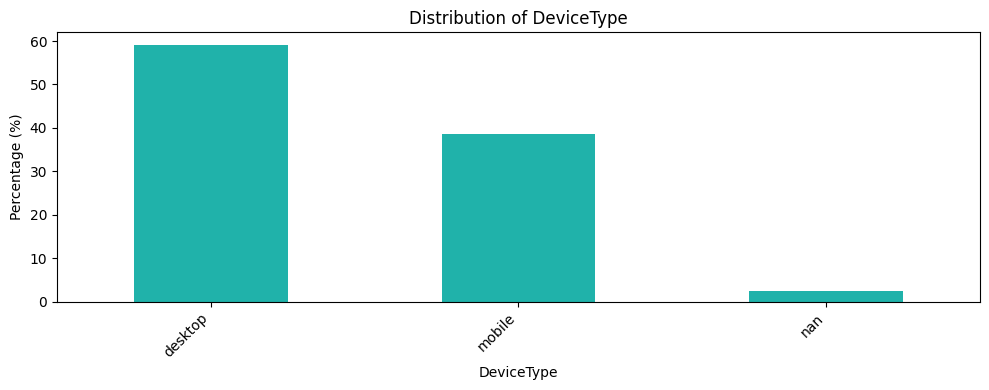


DeviceInfo


,percentage
DeviceInfo,
Windows,33.09
NaN,17.73
iOS Device,13.72
MacOS,8.72
Trident/7.0,5.16
rv:11.0,1.32
rv:57.0,0.67
SM-J700M Build/MMB29K,0.38
SM-G610M Build/MMB29K,0.32


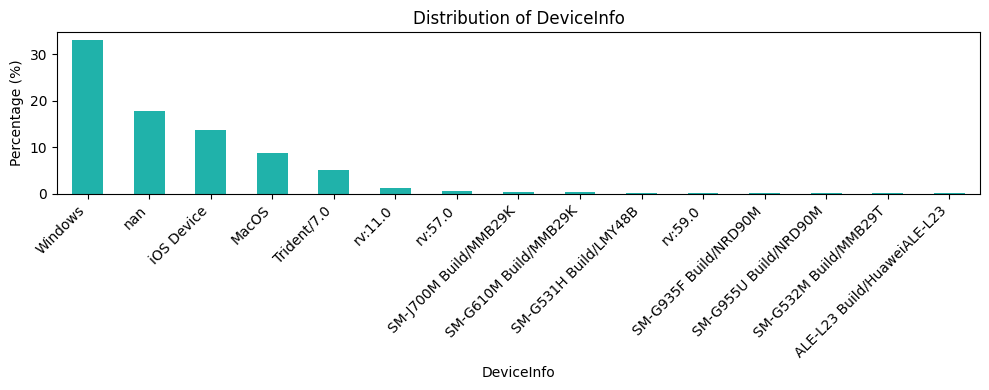


id_30


,percentage
id_30,
NaN,46.22
Windows 10,14.67
Windows 7,9.09
iOS 11.2.1,2.58
iOS 11.1.2,2.56
Android 7.0,1.99
Mac OS X 10_12_6,1.77
Mac OS X 10_11_6,1.63
iOS 11.3.0,1.40


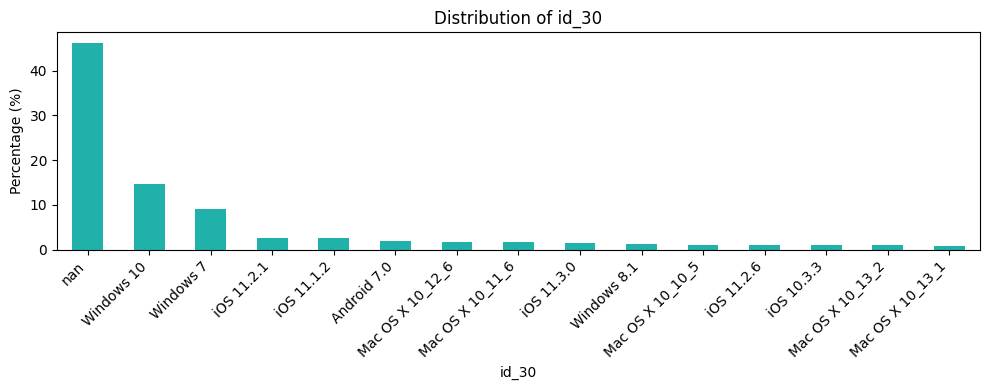


id_31


,percentage
id_31,
chrome 63.0,15.25
mobile safari 11.0,9.31
mobile safari generic,7.96
ie 11.0 for desktop,6.26
safari generic,5.68
chrome 62.0,4.98
chrome 65.0,4.76
chrome 64.0,4.65
chrome 63.0 for android,4.03


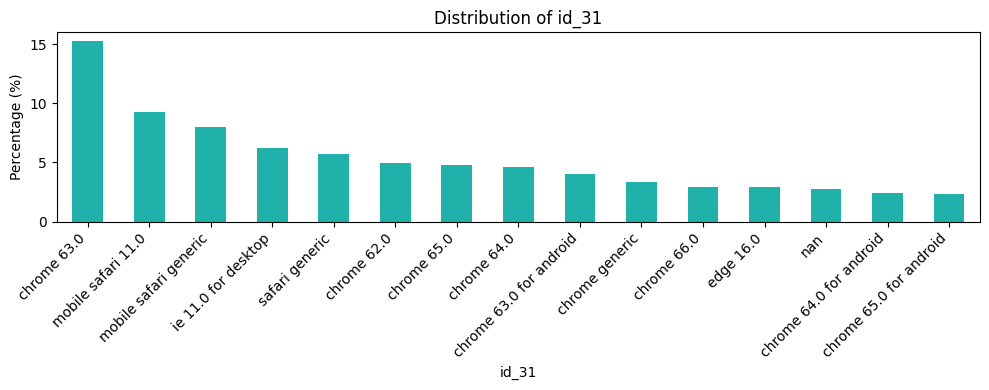

In [12]:
device_cols = ["DeviceType", "DeviceInfo", "id_30", "id_31"]

for col in device_cols:
    print(f"\n{col}")

    stats = (
        df_identity[col]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .head(15)
        .round(2)
    )

    display(stats.to_frame("percentage"))

    plt.figure(figsize=(10, 4))
    stats.plot(kind="bar")

    plt.title(f"Distribution of {col}")
    plt.ylabel("Percentage (%)")
    plt.xlabel(col)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

In [13]:
browser_by_device = pd.crosstab(
    df_identity["DeviceType"],
    df_identity["id_31"],
    normalize="index"
) * 100

top_browsers = df_identity["id_31"].value_counts().head(10).index

browser_by_device[top_browsers].round(2)

id_31,chrome 63.0,mobile safari 11.0,mobile safari generic,ie 11.0 for desktop,safari generic,chrome 62.0,chrome 65.0,chrome 64.0,chrome 63.0 for android,chrome generic
DeviceType,,,,,,,,,,
desktop,25.64,0.00,0.00,10.61,9.67,8.34,7.88,7.71,0.00,4.23
mobile,0.50,24.18,20.67,0.00,0.00,0.20,0.35,0.32,10.46,2.15


In [14]:
os_by_device = pd.crosstab(
    df_identity["DeviceType"],
    df_identity["id_30"],
    normalize="index"
) * 100

top_os = df_identity["id_30"].value_counts().head(10).index

os_by_device[top_os].round(2)

id_30,Windows 10,Windows 7,iOS 11.2.1,iOS 11.1.2,Android 7.0,Mac OS X 10_12_6,Mac OS X 10_11_6,iOS 11.3.0,Windows 8.1,Mac OS X 10_10_5
DeviceType,,,,,,,,,,
desktop,41.13,25.49,0.00,0.00,0.00,4.98,4.55,0.00,3.69,3.21
mobile,0.00,0.00,14.24,14.15,10.98,0.00,0.03,7.71,0.06,0.00


In [15]:
device_profiles = (
    df_identity
    .groupby(
        ["DeviceType", "id_30", "id_31"],
        dropna=False
    )
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

device_profiles["percentage"] = (device_profiles["count"] / len(df_identity) * 100)

device_profiles.head(20)

,DeviceType,id_30,id_31,count,percentage
448,desktop,NaN,chrome 63.0,9490,6.579632
295,desktop,Windows 10,chrome 63.0,5822,4.036524
917,mobile,NaN,mobile safari generic,4962,3.440267
362,desktop,Windows 7,ie 11.0 for desktop,4522,3.135205
449,desktop,NaN,chrome 64.0,4127,2.861342
893,mobile,NaN,chrome 63.0 for android,4104,2.845396
450,desktop,NaN,chrome 65.0,3803,2.636706
343,desktop,Windows 7,chrome 63.0,3579,2.481402
307,desktop,Windows 10,edge 16.0,3559,2.467535
936,NaN,NaN,NaN,3373,2.338577


In [16]:
print("Unique device profiles:", len(device_profiles))

print("Top 20 profiles coverage:", round(device_profiles.head(20)["percentage"].sum(), 2), "%")

Unique device profiles: 937
Top 20 profiles coverage: 51.51 %


In [17]:
device_amount_stats = (
    df_merged
    .groupby("DeviceType")["TransactionAmt"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

device_amount_stats

,count,mean,median,std
DeviceType,,,,
desktop,85165,92.6,54.44,110.25
mobile,55645,69.5,46.42,79.39


In [18]:
product_by_device = pd.crosstab(
    df_merged["DeviceType"],
    df_merged["ProductCD"],
    normalize="index"
) * 100

product_by_device.round(2)

ProductCD,C,H,R,S
DeviceType,,,,
desktop,37.39,22.32,29.48,10.81
mobile,52.42,23.52,20.35,3.71


In [19]:
fraud_by_device = (
    df_merged
    .groupby("DeviceType")["isFraud"]
    .agg(["count", "sum", "mean"])
)

fraud_by_device["fraud_rate_pct"] = (
    fraud_by_device["mean"] * 100
)

fraud_by_device.round(2)

,count,sum,mean,fraud_rate_pct
DeviceType,,,,
desktop,85165,5554,0.07,6.52
mobile,55645,5657,0.10,10.17


In [20]:
df_merged["has_identity"] = df_merged["TransactionID"].isin(
    df_identity["TransactionID"]
)

identity_fraud = (
    df_merged
    .groupby("has_identity")["isFraud"]
    .agg(["count", "sum", "mean"])
)

identity_fraud["fraud_rate_pct"] = (
    identity_fraud["mean"] * 100
)

identity_fraud.round(2)

,count,sum,mean,fraud_rate_pct
has_identity,,,,
False,446307,9345,0.02,2.09
True,144233,11318,0.08,7.85
